# 04 — Feature Engineering (Phase 2)

Phase 1 showed *which* external sources carry a signal. This notebook turns the enriched stop events into **model-ready,
leakage-safe features**. The code lives in `src/features.py` (build) and `src/encoding.py` (model-specific encodings);
the leakage logic is unit-tested in `tests/test_leakage.py`.

> **What** · **Why** · **How** · **Result** · **Finding** · **Decision**

### The guiding rule
Every feature must be something a transit agency **would actually know at the moment it makes the prediction**.
That gives two prediction modes:

| Mode | Agency user | Prediction moment | Information allowed |
|---|---|---|---|
| **Planning** (day-ahead) | Service planners, rider alerts for tomorrow | the day before | calendar, route/stop/schedule, historical rates up to yesterday, weather (as forecast), events, previous-season ridership |
| **Operational** (minutes-ahead) | Dispatchers / bus operations centre | bus leaves its previous timepoint | planning + the bus's delay at the previous timepoint, its delay at trip start, the last bus that *already* passed this stop |

In [1]:
import sys, json, warnings
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score
from src.config import REPORTS, FIG_DIR
from src.encoding import load_split, spec
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save(n): plt.tight_layout(); plt.savefig(FIG_DIR / f'p2_{n}.png', bbox_inches='tight'); plt.show()
S = spec()
pd.DataFrame([(g, len(f), ', '.join(f)) for g, f in S['groups'].items()], columns=['group', 'n', 'features'])

,group,n,features
0,temporal,7,"hour_sin, hour_cos, dow, is_weekend, am_peak, ..."
1,calendar,6,"is_holiday, is_school_day, is_university_term,..."
2,daylight,3,"sun_elevation, is_dark, dark_peak"
3,spatial,12,"route_id, direction_id, stop_id, time_point_or..."
4,history,9,"hist_route_hour, hist_route_dow, hist_stop_per..."
5,weather,8,"precipitation, precip_3h, snow_24h, snow_depth..."
6,events,2,"venue_event_nearby, citywide_event"
7,gtfs,4,"segment_km, stops_between, seg_sched_min, sche..."
8,ridership,4,"avg_load, avg_boardings, avg_alightings, load_..."
9,operational,6,"prev_tp_delay, prev_tp_delayed, start_delay, p..."


## 1. Time-based split
**What:** train = Jan–Aug 2025, validation = Sep–Oct 2025, test = Nov–Dec 2025; 2024 kept separately for the drift experiment.
**Why:** a random split would let the model see the *same day* (same weather, same incident) in train and test, which
inflates accuracy. An agency always predicts the future from the past, so we evaluate the same way.

,rows,pct_delayed,from,to
train,6448156,28.75,2025-01-01,2025-08-31
valid,1690047,32.77,2025-09-01,2025-10-31
test,1685083,25.05,2025-11-01,2025-12-31


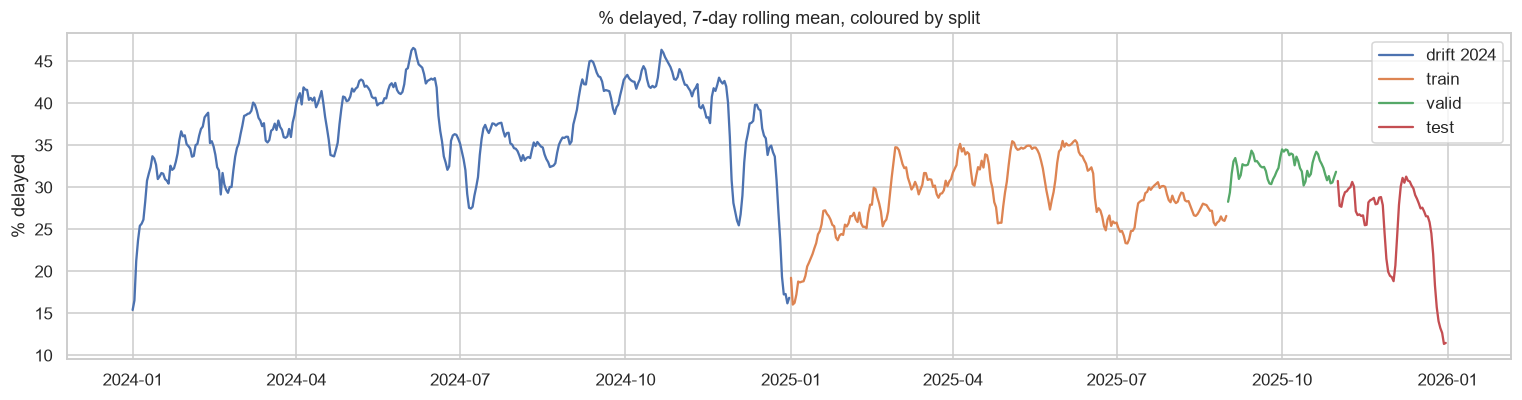

In [2]:
sp = pd.DataFrame(S['splits']).T
sp['rows'] = sp.rows.astype(int); display(sp)
tr = load_split('train', sample=1_000_000); va = load_split('valid', sample=400_000); te = load_split('test', sample=400_000)
dr = load_split('drift_2024', sample=600_000)
fig, ax = plt.subplots(figsize=(14, 3.8))
for name, d in [('drift 2024', dr), ('train', tr), ('valid', va), ('test', te)]:
    s = d.groupby('service_date').delayed.mean().mul(100).rolling(7, min_periods=1).mean()
    ax.plot(s.index, s.values, label=name)
ax.set(title='% delayed, 7-day rolling mean, coloured by split', ylabel='% delayed'); ax.legend(); save('splits')

**Finding.** The three 2025 splits do **not** share the same delay rate: train 28.8 %, validation **32.8 %** (busy Sep–Oct, school and
university back), test **25.1 %** (calmer Nov–Dec, holidays). This is a realistic, hard setting. The model is tuned on a busier period than
it is tested on.
**Decision:**
1. Use **ROC-AUC and PR-AUC** (threshold-free) as the main comparison metrics.
2. Check **calibration** on the test set. A model calibrated on Sep–Oct may over-predict in Nov–Dec.
3. The 28-day rolling rates (below) let the model adapt its level as the season changes.

## 2. Temporal features
**What:** hour encoded as `sin/cos` of the scheduled time, weekday, weekend, AM/PM peak flags (weekdays only), a service period, and the
`school_dismissal` flag (school day and 14:00–15:59, a Phase 1 finding).
**Why cyclical:** with a plain hour number, 23:00 and 00:00 look 23 units apart. On the circle they are neighbours, which matters for the linear model.
**Why no month:** training covers Jan–Aug and the test covers Nov–Dec. A month feature would ask trees to extrapolate to values they never saw.
Seasonality is instead carried by the **school/university calendar** and the **recent 28-day delay rate**.

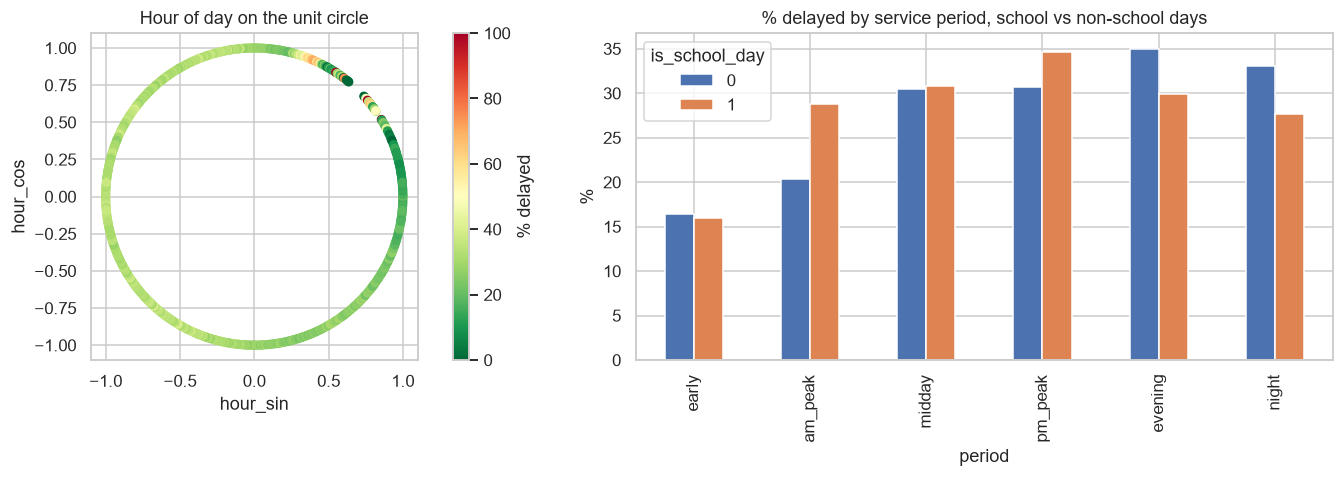

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
g = tr.groupby(tr.hour_sin.round(2).astype(str) + tr.hour_cos.round(2).astype(str)).agg(s=('hour_sin','mean'), c=('hour_cos','mean'), y=('delayed','mean'))
sc = axes[0].scatter(g.s, g.c, c=g.y*100, cmap='RdYlGn_r', s=25); plt.colorbar(sc, ax=axes[0], label='% delayed')
axes[0].set(title='Hour of day on the unit circle', xlabel='hour_sin', ylabel='hour_cos', aspect='equal')
p = tr.groupby(['period', 'is_school_day'], observed=True).delayed.mean().unstack().mul(100)
p = p.loc[['early','am_peak','midday','pm_peak','evening','night']]
p.plot.bar(ax=axes[1]); axes[1].set(title='% delayed by service period, school vs non-school days', ylabel='%')
save('temporal')

**Finding.** On the circle, the low-risk early-morning hours sit next to the late-night hours, exactly the neighbourhood a plain hour number
would break. By period, school days are clearly worse in the **AM peak (29 % vs 20 %)** and somewhat worse in the **PM peak (35 % vs 31 %)**.
Evenings and nights are *better* on school days, because many non-school days are weekends with heavier evening traffic.
**Decision:** keep `period`, the peak flags and `school_dismissal`. The school effect depends on time of day, which is why tree models
(which learn interactions) are expected to beat logistic regression.

## 3. Historical delay rates (the most important and most dangerous features)
**What:** for each key, the share of delayed stop events on **all previous days**, plus the share over the **last 28 days**:

| Feature | Key | Window |
|---|---|---|
| `hist_route_hour` | route × hour | expanding |
| `hist_route_dow` | route × weekday | expanding |
| `hist_stop_period` | route × direction × stop × period | expanding |
| `hist_stop_hour` (+ `_n` = log #obs) | route × direction × stop × hour | expanding |
| `hist_delay_route_hour`, `hist_delay_stop_hour` | same keys, mean delay (min) | expanding |
| `recent_route_28d`, `recent_stop_28d` | route; route × direction × stop | last 28 days |

**How (leakage-safe):** daily sums and counts, cumulative sum **minus today**, so a row only ever sees days strictly before its service date.
Rates are **smoothed** toward the global rate known so far:
$\hat p = (\text{late}_{<D} + m\,\bar p_{<D}) / (n_{<D} + m)$ with $m = 30$. Rare combinations therefore don't get extreme values.
History is **seeded with 2024**, so the first 2025 days already have a full year behind them.

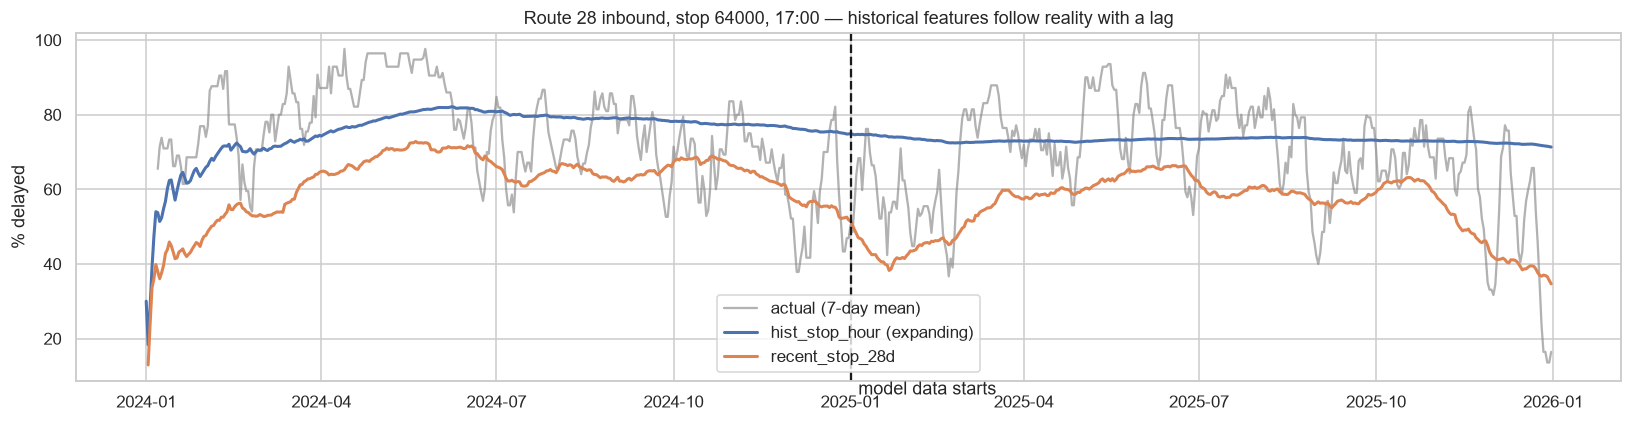

In [4]:
# Example: one busy key — the expanding and rolling features vs the actual daily rate
key = dict(route_id='28', direction_id='Inbound')
cols = ['service_date','route_id','direction_id','stop_id','hour','delayed','hist_stop_hour','recent_stop_28d']
full = pd.concat([pd.read_parquet(f'../data/processed/features/{s}.parquet', columns=cols) for s in ('drift_2024','train','valid','test')])
k = full[(full.route_id == '28') & (full.direction_id == 'Inbound')]
top_stop = k.stop_id.value_counts().index[0]; k = k[(k.stop_id == top_stop) & (k.hour == 17)]
d = k.groupby('service_date').agg(actual=('delayed','mean'), exp_rate=('hist_stop_hour','first'), rolling28=('recent_stop_28d','first'))
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(d.index, d.actual.rolling(7).mean()*100, color='grey', alpha=.6, label='actual (7-day mean)')
ax.plot(d.index, d.exp_rate*100, lw=2, label='hist_stop_hour (expanding)'); ax.plot(d.index, d.rolling28*100, lw=2, label='recent_stop_28d')
ax.axvline(pd.Timestamp('2025-01-01'), color='k', ls='--'); ax.text(pd.Timestamp('2025-01-05'), 5, 'model data starts')
ax.set(title=f'Route 28 inbound, stop {top_stop}, 17:00 — historical features follow reality with a lag', ylabel='% delayed'); ax.legend()
save('history_example')
del full

**Finding.** On this chronically late stop (route 28 inbound, 17:00), the expanding rate settles around 72–75 % and then barely moves
in 2025. It **cannot follow** the 2024→2025 improvement or the calm end of December. The 28-day rolling rate tracks the actual level within
weeks (≈ 60 % through most of 2025, falling to ≈ 35 % in late December). Both are useful: the expanding rate says *where/when is structurally bad*,
the rolling rate says *how the system is doing right now*.

### 3b. Leakage demonstration: what happens if we compute the rate the naïve way?
**What:** compare our leakage-safe `hist_stop_hour` with a naïve version computed over the **whole test period including the row itself**
(a classic mistake: `groupby(key).delayed.transform('mean')`).
**Why:** to show quantitatively why the expanding window is needed. The naïve feature looks better offline but could never be computed in deployment.

In [5]:
te_full = load_split('test', columns=['route_id','direction_id','stop_id','hour','service_date','delayed','hist_stop_hour','recent_stop_28d'])
naive_all = te_full.groupby(['route_id','direction_id','stop_id','hour'], observed=True).delayed.transform('mean')
naive_day = te_full.groupby(['route_id','direction_id','stop_id','hour','service_date'], observed=True).delayed.transform('mean')
res = pd.Series({
    'hist_stop_hour (safe, expanding, days < D)': roc_auc_score(te_full.delayed, te_full.hist_stop_hour),
    'recent_stop_28d (safe, 28 days < D)': roc_auc_score(te_full.delayed, te_full.recent_stop_28d),
    'naïve: same key over whole test period (leaky)': roc_auc_score(te_full.delayed, naive_all),
    'naïve: same key, same day incl. own row (very leaky)': roc_auc_score(te_full.delayed, naive_day),
}, name='ROC-AUC on test').round(3)
res.to_frame()

,ROC-AUC on test
"hist_stop_hour (safe, expanding, days < D)",0.657
"recent_stop_28d (safe, 28 days < D)",0.682
naïve: same key over whole test period (leaky),0.721
"naïve: same key, same day incl. own row (very leaky)",0.898


**Finding.** The safe features reach AUC 0.66 (expanding) and 0.68 (28-day). The leaky "whole-period" version reaches 0.72, and the
same-day version **0.90**, because it uses the day's own incidents and even the row's own label. A model built on such features would report
excellent offline accuracy and then fail in production, where those values are unknown.
**Decision:** only the strictly-past versions are used. `tests/test_leakage.py` proves the property: changing any label on day D or later leaves
all features up to D unchanged, and the operational features never read the bus's own arrival.

## 4. Operational (real-time) features
**What:** `prev_tp_delay` (this bus's delay at the previous timepoint), `start_delay` (delay at trip start), `min_since_prev_tp`
(scheduled minutes from the previous departure to this stop), `prev_bus_delay` (delay of the last bus that **already passed** this stop
before our bus left its previous timepoint), and `prev_bus_gap_ratio` (time since that bus passed ÷ planned headway; > 1 means a gap is opening).
**Why:** EDA showed delay **propagates** along the trip (start→end r = 0.58). Dispatchers see these values live in the AVL system.

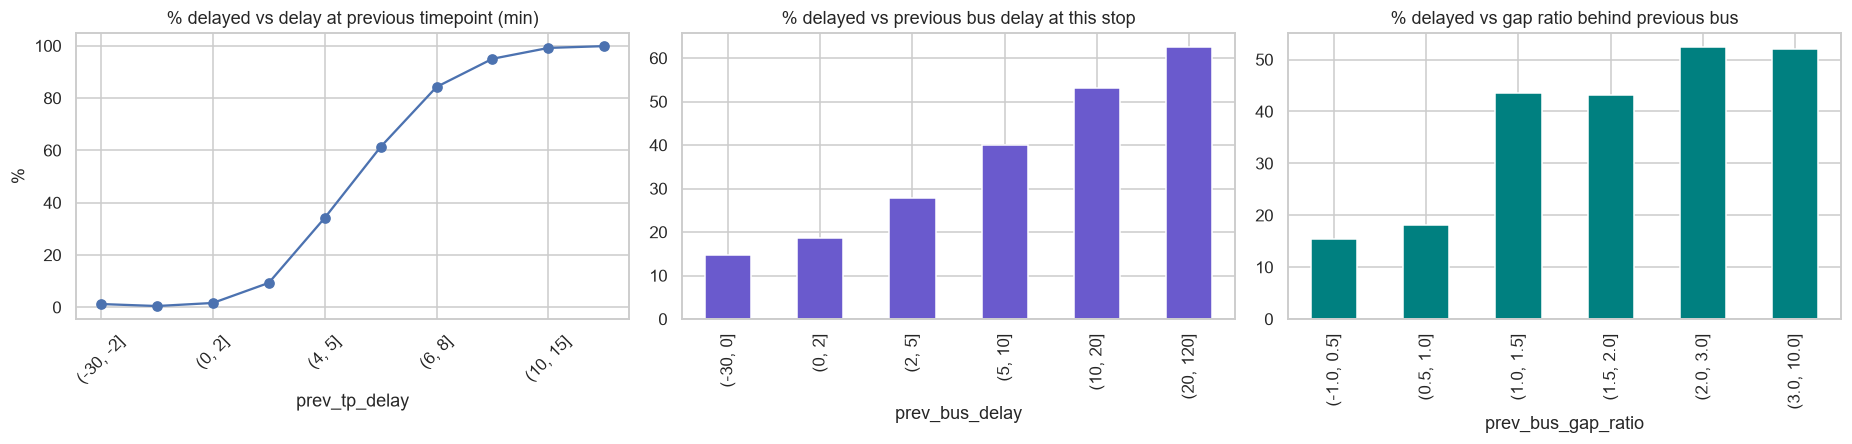

missing share: {'prev_tp_delay': 0.119, 'prev_tp_delayed': 0.119, 'start_delay': 0.119, 'prev_bus_delay': 0.024, 'prev_bus_gap_ratio': 0.024, 'min_since_prev_tp': 0.119}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
b = pd.cut(te.prev_tp_delay, [-30, -2, 0, 2, 4, 5, 6, 8, 10, 15, 120])
(te.groupby(b, observed=True).delayed.mean()*100).plot(ax=axes[0], marker='o'); axes[0].set(title='% delayed vs delay at previous timepoint (min)', ylabel='%'); axes[0].tick_params(axis='x', rotation=45)
b = pd.cut(te.prev_bus_delay, [-30, 0, 2, 5, 10, 20, 120])
(te.groupby(b, observed=True).delayed.mean()*100).plot.bar(ax=axes[1], color='slateblue'); axes[1].set(title='% delayed vs previous bus delay at this stop')
b = pd.cut(te.prev_bus_gap_ratio, [-1, .5, 1, 1.5, 2, 3, 10])
(te.groupby(b, observed=True).delayed.mean()*100).plot.bar(ax=axes[2], color='teal'); axes[2].set(title='% delayed vs gap ratio behind previous bus')
save('operational')
print('missing share:', te[S['groups']['operational']].isna().mean().round(3).to_dict())

**Finding.** `prev_tp_delay` is close to deterministic. Below 2 min late almost nobody becomes > 5 min late at the next timepoint, at 6–8 min
84 % do, and above 10 min ≈ 99 % do. The previous bus matters too: if it was > 20 min late, our bus is late 62 % of the time (vs 15 %
when it was on time). If the previous bus passed more than one planned headway ago (gap ratio > 1), the risk jumps from ≈ 17 % to 43–52 %:
a gap has opened, so our bus picks up more passengers (**bunching dynamics**).
**Decision:** these are **operational-only**. The thesis will report both modes, because comparing them answers an agency question:
*how much does live AVL data improve the forecast over day-ahead planning?*
`prev_tp_delay` is missing at the first timepoint of each trip. That is expected, and handled by NaN-aware trees, or imputation plus a missing-flag for LR.

## 5. Univariate signal of every feature
**What:** the ROC-AUC of each numeric feature *on its own* (train sample), shown as $\max(\text{AUC}, 1-\text{AUC})$ so direction doesn't matter.
**Why:** a quick, model-free ranking. It catches dead features and suspiciously strong (leaky) ones before modelling.

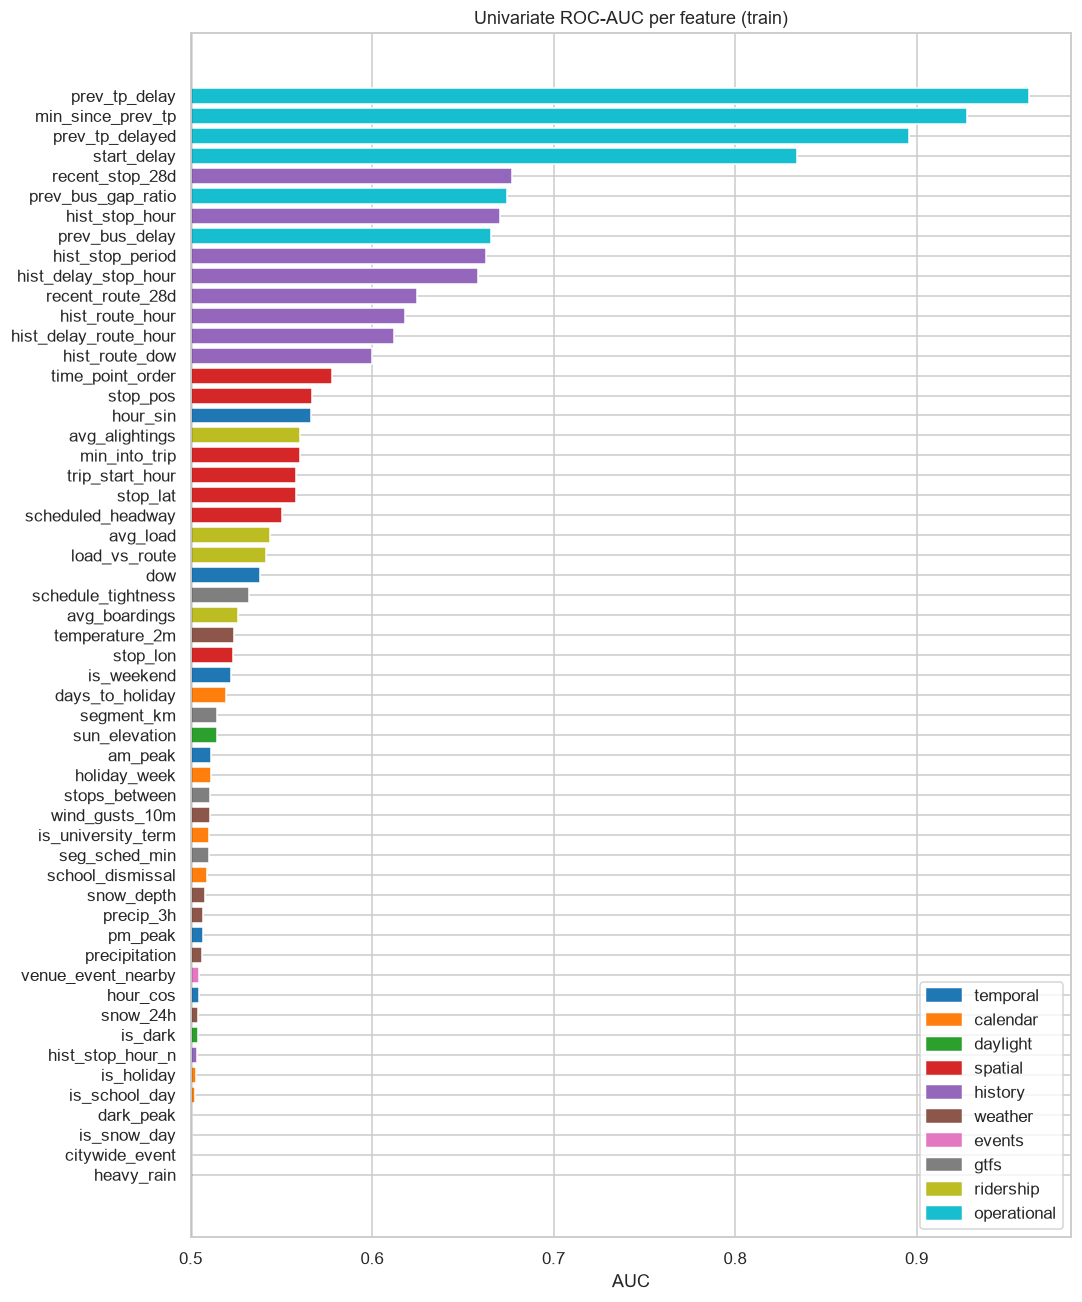

,best AUC in group
group,
operational,0.962
history,0.677
spatial,0.578
temporal,0.566
ridership,0.561
gtfs,0.532
weather,0.524
calendar,0.519
daylight,0.515


In [7]:
grp_of = {f: g for g, fs in S['groups'].items() for f in fs}
rows = []
for f in S['operational']:
    if f in S['categorical']: continue
    x = tr[f]; m = x.notna()
    if x[m].nunique() < 2: continue
    a = roc_auc_score(tr.delayed[m], x[m]); rows.append((f, grp_of[f], max(a, 1-a), 1 - m.mean()))
ua = pd.DataFrame(rows, columns=['feature','group','auc','missing']).sort_values('auc', ascending=False)
ua.to_csv(REPORTS / 'univariate_auc.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 12))
pal = dict(zip(S['groups'], sns.color_palette('tab10', len(S['groups']))))
ax.barh(ua.feature, ua.auc - .5, left=.5, color=[pal[g] for g in ua.group]); ax.invert_yaxis()
ax.axvline(.5, color='k'); ax.set(title='Univariate ROC-AUC per feature (train)', xlabel='AUC')
from matplotlib.patches import Patch; ax.legend(handles=[Patch(color=c, label=g) for g, c in pal.items()], loc='lower right')
save('univariate_auc')
ua.groupby('group').auc.max().sort_values(ascending=False).round(3).to_frame('best AUC in group')

**Finding.** The ranking matches the Phase 1 story, with one important nuance.
- **Operational** features dominate (best AUC 0.96). `min_since_prev_tp` (0.93) is essentially the mirror image of `prev_tp_delay`:
  how much scheduled time is left after the bus actually left the previous timepoint.
- Among **planning** features, the **historical rates** are clearly strongest (0.60–0.68). The 28-day rolling stop rate is the single best planning feature.
- Next come spatial (0.58), temporal (0.57), ridership (0.56), GTFS (0.53), weather (0.52), calendar (0.52) and events (0.50).
- **Nuance:** `is_school_day` alone is ≈ 0.50 even though Phase 1 showed school days are ≈ 5 pp worse *on weekdays*. Mixed over all days the
  effect cancels, because weekends (non-school days) are also bad. Its value lies in **interactions** (school day × peak hour), which a
  univariate test cannot see but trees can. The same applies to events, which are rare but locally strong.

No planning feature is suspiciously close to 1, which is consistent with the leakage tests.
**Decision:** do not drop features on univariate AUC. Feature value is decided by the **ablation study** in Phase 3, where groups are added one at a time to a multivariate model.

## 6. Redundancy among historical features
**What:** Spearman correlation among the history features.
**Why:** highly correlated features split SHAP credit between them and make LR coefficients unstable. We need to know this before reading explanations.

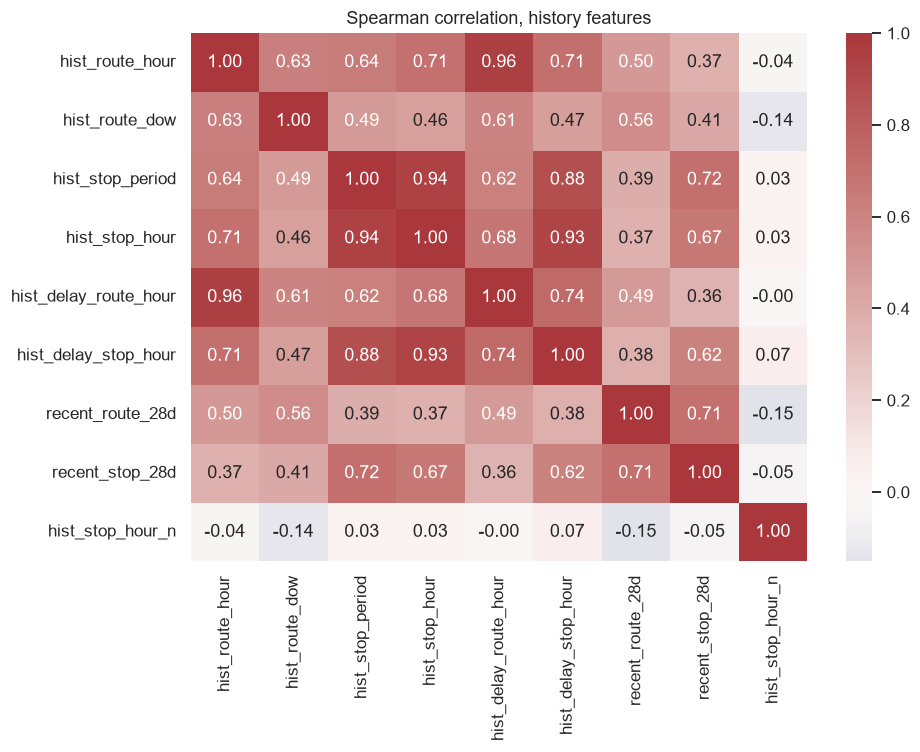

In [8]:
h = S['groups']['history']
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(tr[h].corr('spearman'), annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax); ax.set_title('Spearman correlation, history features')
save('history_corr')

**Finding.** The stop-level expanding rates are near-duplicates (`hist_stop_hour` vs `hist_stop_period` ρ = 0.94, vs `hist_delay_stop_hour` 0.93),
and so are the route-level ones (`hist_route_hour` vs `hist_delay_route_hour` 0.96). The 28-day rolling rates are only moderately correlated
with the expanding ones (0.37–0.72), so they carry **new information** (the current level). `hist_stop_hour_n` is independent (≈ 0).
**Decision:** keep all of them for the tree models (they cope with redundancy), but interpret SHAP **per group** (summing SHAP values within a
feature group) as well as per feature. Logistic regression uses L2 regularisation, which stabilises correlated coefficients.

## 7. Missing values and encodings
**Why:** the two model families need different input formats. Missingness itself is explained: GTFS segment features are missing at the first
timepoint (no previous segment) plus about 5 % unmatched pairs (16.7 % total). Operational "previous timepoint" features are missing at trip
start (12 %). Ridership is missing where a stop/hour had no APC sample (5.9 %).

In [9]:
miss = tr[S['operational']].isna().mean().mul(100).round(2)
display(miss[miss > 0].sort_values(ascending=False).to_frame('% missing (train)'))
pd.DataFrame({
    'Model family': ['Logistic regression', 'Decision tree / Random forest', 'XGBoost'],
    'Categoricals': ['one-hot (rare levels < 50 rows pooled)', 'integer codes', 'native categorical splits'],
    'Missing values': ['median impute + missing-indicator column', 'sentinel −999 (own branch)', 'native (learned default direction)'],
    'Scaling': ['standardised', 'none', 'none'],
    'Code': ['encoding.linear_preprocessor', 'encoding.tree_matrix', 'enable_categorical=True'],
})

,% missing (train)
stops_between,16.68
schedule_tightness,16.68
segment_km,16.68
start_delay,12.02
seg_sched_min,12.02
prev_tp_delay,12.02
min_since_prev_tp,12.02
prev_tp_delayed,12.02
avg_alightings,5.90
avg_boardings,5.90


,Model family,Categoricals,Missing values,Scaling,Code
0,Logistic regression,one-hot (rare levels < 50 rows pooled),median impute + missing-indicator column,standardised,encoding.linear_preprocessor
1,Decision tree / Random forest,integer codes,sentinel −999 (own branch),none,encoding.tree_matrix
2,XGBoost,native categorical splits,native (learned default direction),none,enable_categorical=True


## 8. Daylight and the daylight-saving change
**What:** `sun_elevation` (degrees, NOAA solar-position formula, per scheduled minute at Boston's coordinates), `is_dark`
(sun below −6°, i.e. after civil twilight) and `dark_peak` (dark during the AM or PM peak).
**Why:** the test period (Nov–Dec) begins right after the **2 Nov 2025 clock change**, which puts the whole PM peak in darkness.
Darkness lowers driving speed and visibility at stops. Clock-based hour features cannot see this: 17:00 is the same "hour" in October and in November.
Tested in `tests/test_daylight.py` against known solar-noon elevations and the DST switch.

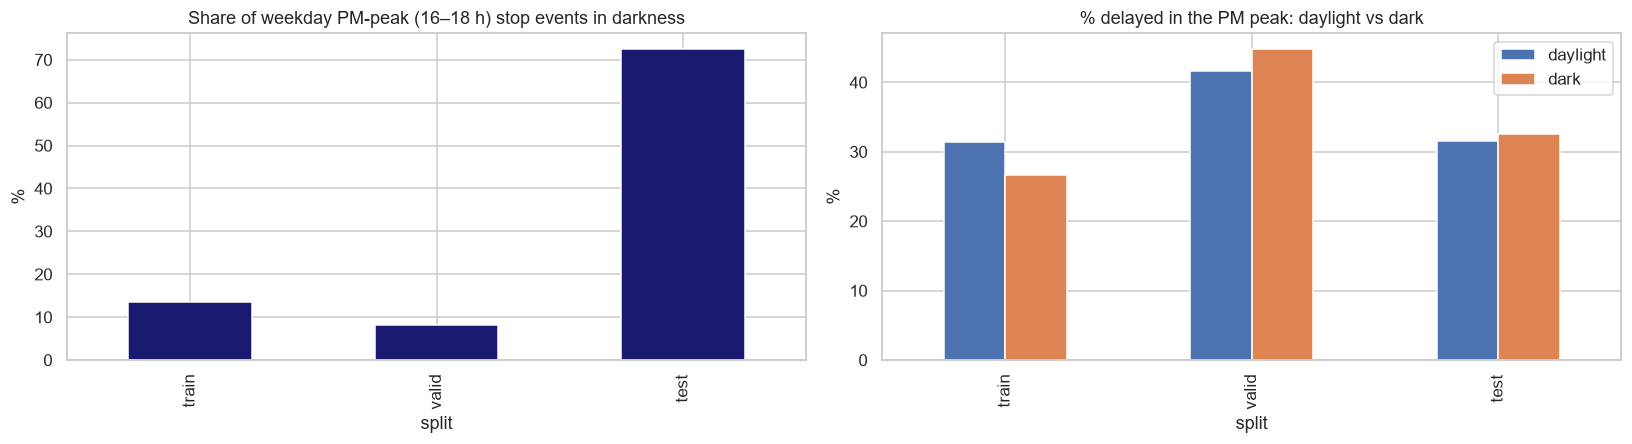

% of weekday PM-peak stop events in darkness: {'train': 13.6, 'valid': 8.2, 'test': 72.6}


,daylight,dark
split,,
train,31.4,26.7
valid,41.7,44.8
test,31.6,32.6


In [10]:
d = pd.concat([tr.assign(split='train'), va.assign(split='valid'), te.assign(split='test')])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
pm = d[d.hour.between(16, 18) & (d.is_weekend == 0)]
(pm.groupby(['split'], observed=True).is_dark.mean()*100).reindex(['train','valid','test']).plot.bar(ax=axes[0], color='midnightblue')
axes[0].set(title='Share of weekday PM-peak (16–18 h) stop events in darkness', ylabel='%')
g = pm.groupby(['split','is_dark']).delayed.mean().unstack().mul(100).reindex(['train','valid','test'])
g.columns = ['daylight', 'dark']; g.plot.bar(ax=axes[1]); axes[1].set(title='% delayed in the PM peak: daylight vs dark', ylabel='%')
save('daylight')
print('% of weekday PM-peak stop events in darkness:', (pm.groupby('split', observed=True).is_dark.mean()*100).reindex(['train','valid','test']).round(1).to_dict())
g.round(1)

**Finding.** Darkness in the weekday PM peak (16–18 h) covers **13.6 %** of training events and **8.2 %** of validation events, but
**72.6 %** of test events. This is the biggest calendar-driven difference between the periods. Within a split, dark evenings are only
slightly worse in validation (44.8 % vs 41.7 % delayed) and in test (32.6 % vs 31.6 %). In training they are *better* (26.7 % vs 31.4 %),
because the dark training evenings are quiet January–February days. So darkness alone is a weak, season-confounded signal.
**Decision.** Keep the daylight group because it is cheap and physically meaningful. Phase 3's ablation measures whether it helps on Nov–Dec.
We expect at most a small gain, because the model has seen very few dark *busy* evenings.

## 9. Seasonal shift check (adversarial validation)
**What:** train a classifier to tell **training rows (Jan–Aug)** from **test rows (Nov–Dec)** using the planning features.
**Why:** if the two periods were alike, the classifier would score AUC ≈ 0.5. A high AUC means the test conditions differ, and its feature
importance shows *which* features shifted, so we know where the model must extrapolate.

In [11]:
import xgboost as xgb
from src.encoding import align_categories
feats = [f for f in S['planning'] if f not in ('route_id','stop_id','direction_id')]
a = tr.sample(200_000, random_state=1).assign(is_test=0); b = te.sample(200_000, random_state=1).assign(is_test=1)
ab = pd.concat([a, b]).sample(frac=1, random_state=1)
cut = int(len(ab) * .7)
m = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=.1, tree_method='hist', enable_categorical=True, n_jobs=-1)
m.fit(ab[feats][:cut], ab.is_test[:cut])
adv_auc = roc_auc_score(ab.is_test[cut:], m.predict_proba(ab[feats][cut:])[:, 1])
imp = pd.Series(m.get_booster().get_score(importance_type='gain')).sort_values(ascending=False)
print(f'Adversarial AUC (train vs test, all planning features): {adv_auc:.3f}')
display((imp / imp.sum() * 100).head(10).round(1).to_frame('% of gain'))

# without the obviously date-dependent features (rolling rates, history counts, temperature, daylight)
drop = {'recent_route_28d','recent_stop_28d','hist_stop_hour_n','temperature_2m','sun_elevation','is_dark','dark_peak',
        'snow_depth','is_university_term','days_to_holiday','holiday_week'}
f2 = [f for f in feats if f not in drop]
m2 = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=.1, tree_method='hist', enable_categorical=True, n_jobs=-1)
m2.fit(ab[f2][:cut], ab.is_test[:cut])
print(f'Adversarial AUC without seasonal/date-dependent features: {roc_auc_score(ab.is_test[cut:], m2.predict_proba(ab[f2][cut:])[:, 1]):.3f}')
imp2 = pd.Series(m2.get_booster().get_score(importance_type='gain')).sort_values(ascending=False)
display((imp2 / imp2.sum() * 100).head(8).round(1).to_frame('% of gain (reduced set)'))

Adversarial AUC (train vs test, all planning features): 1.000


,% of gain
hist_stop_hour_n,15.0
temperature_2m,14.7
standard_type,7.3
seg_sched_min,7.2
days_to_holiday,5.2
is_university_term,5.1
is_school_day,4.9
stop_lon,4.1
snow_depth,3.9
scheduled_headway,3.3


Adversarial AUC without seasonal/date-dependent features: 0.992


,% of gain (reduced set)
venue_event_nearby,8.7
snow_24h,6.0
hist_route_dow,5.9
dow,5.5
citywide_event,4.6
is_school_day,4.3
stop_lon,4.0
wind_gusts_10m,4.0


In [12]:
# covariate overlap: are test values inside the training range?
rows = []
for f in ['temperature_2m', 'sun_elevation', 'precip_3h', 'snow_24h', 'avg_load', 'recent_route_28d', 'hist_stop_hour']:
    lo, hi = tr[f].quantile([.005, .995])
    rows.append((f, f'{lo:.2f} – {hi:.2f}', f"{te[f].min():.2f} – {te[f].max():.2f}", (te[f].between(lo, hi) | te[f].isna()).mean()*100))
pd.DataFrame(rows, columns=['feature', 'train 0.5–99.5 %', 'test min – max', '% test rows inside train range']).round(1)

,feature,train 0.5–99.5 %,test min – max,% test rows inside train range
0,temperature_2m,-11.70 – 34.50,-11.70 – 16.30,100.0
1,sun_elevation,-67.21 – 70.11,-71.06 – 33.38,95.4
2,precip_3h,0.00 – 10.80,0.00 – 15.70,100.0
3,snow_24h,0.00 – 7.98,0.00 – 5.25,100.0
4,avg_load,0.00 – 39.27,0.00 – 47.11,99.6
5,recent_route_28d,0.12 – 0.55,0.10 – 0.49,94.0
6,hist_stop_hour,0.05 – 0.71,0.01 – 0.93,99.1


**Finding.** The adversarial classifier separates Jan–Aug from Nov–Dec **perfectly (AUC 1.000)**. The top features are
`hist_stop_hour_n` (a counter that grows over time), temperature, and the schedule descriptors `standard_type` / `seg_sched_min`.
Schedule descriptors shift because the MBTA publishes a new schedule each season (the "rating" that starts in late August).
Removing the obviously date-dependent features leaves AUC at **0.992**. The remaining features that separate the periods are
*day-level* ones (venue events, snow, day of week, wind). With rows sampled at random, each service day's weather/event combination acts
as a fingerprint of that date. So adversarial AUC cannot be pushed towards 0.5 with this kind of data, and it is not by itself evidence of harmful shift.
The **covariate overlap table** is the more useful check. For 6 of the 7 key numeric features, ≥ 95 % of test rows fall inside the central
99 % of training values. The exception is `recent_route_28d` at 94 %. Sun elevation is only 95 % inside because of early winter sunsets.
**Decision.** The test period differs in season and schedule, not in kind. The model mostly interpolates. Three things in Phase 3 handle
the shift: (1) refitting on Jan–Oct, so the autumn schedule is seen; (2) ROC-/PR-AUC plus a calibration check as headline metrics;
(3) the **12-month window** and **walk-forward** experiments, which measure the remaining seasonal risk directly.

## 10. Phase 2 summary

| Item | Result |
|---|---|
| Feature tables | `data/processed/features/{train,valid,test,drift_2024}.parquet` (61 features + ids + targets) |
| Spec | `reports/feature_spec.json`: groups, planning (55) vs operational (61), categoricals |
| Leakage | expanding + rolling windows strictly before D; 7 unit tests in `tests/test_leakage.py`; naïve version shown to inflate AUC |
| Split | train 6.45 M (28.8 %), valid 1.69 M (32.8 %), test 1.69 M (25.1 %); class balance shifts by season |
| Removed on purpose | `month` (no extrapolation), actual `headway`, anything from the bus's own arrival |
| Seasonal shift | daylight features added (DST); adversarial validation and covariate-overlap check |
| Tests | `tests/test_leakage.py`, `tests/test_features.py`, `tests/test_joins.py`, `tests/test_daylight.py` |

**Next (Phase 3 — models):** historical-average baseline (B0) → logistic regression → decision tree → random forest → XGBoost, in both
planning and operational modes; tuning on validation; test-set metrics with confidence intervals; ablation by feature group; the 2024→2025 drift experiment.